# Student Performance Predictor
Predict a student's final grade (G3, scale 0-20) from study habits, family background and attendance.

**Steps:** 1) Load data 2) Explore 3) Prepare 4) Train models 5) Evaluate 6) Feature importance

## 1. Load data
UCI *Student Performance* dataset (math course, 395 students).

In [5]:
import pandas as pd, numpy as np, matplotlib.pyplot as plt, io, zipfile, urllib.request
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, r2_score

def find_csv(data):
    """Search a zip (and any zip inside it) for student-mat.csv."""
    if not zipfile.is_zipfile(io.BytesIO(data)):
        return None
    z = zipfile.ZipFile(io.BytesIO(data))
    for n in z.namelist():
        if n.endswith("student-mat.csv"):
            return z.read(n)
    for n in z.namelist():
        found = find_csv(z.read(n))
        if found:
            return found
    return None

csv_bytes = None
try:
    URL = "https://archive.ics.uci.edu/static/public/320/student+performance.zip"
    csv_bytes = find_csv(urllib.request.urlopen(URL, timeout=30).read())
except Exception as e:
    print("Auto download failed:", e)

if csv_bytes is None:
    print("Upload student.zip OR student-mat.csv")
    from google.colab import files
    for name, content in files.upload().items():
        csv_bytes = find_csv(content) or (content if name.endswith(".csv") else None)
        if csv_bytes:
            break

df = pd.read_csv(io.BytesIO(csv_bytes), sep=";")
print(df.shape)
df.head()

(395, 33)


,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,...,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
0,GP,F,18,U,GT3,A,4,4,at_home,teacher,...,4,3,4,1,1,3,6,5,6,6
1,GP,F,17,U,GT3,T,1,1,at_home,other,...,5,3,3,1,1,3,4,5,5,6
2,GP,F,15,U,LE3,T,1,1,at_home,other,...,4,3,2,2,3,3,10,7,8,10
3,GP,F,15,U,GT3,T,4,2,health,services,...,3,2,2,1,1,5,2,15,14,15
4,GP,F,16,U,GT3,T,3,3,other,other,...,4,3,2,1,2,5,4,6,10,10


## 2. Explore

In [6]:
print(df.shape)
print("Missing values:", df.isna().sum().sum())
df.describe()

(395, 33)
Missing values: 0


,age,Medu,Fedu,traveltime,studytime,failures,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
count,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000
mean,16.696203,2.749367,2.521519,1.448101,2.035443,0.334177,3.944304,3.235443,3.108861,1.481013,2.291139,3.554430,5.708861,10.908861,10.713924,10.415190
std,1.276043,1.094735,1.088201,0.697505,0.839240,0.743651,0.896659,0.998862,1.113278,0.890741,1.287897,1.390303,8.003096,3.319195,3.761505,4.581443
min,15.000000,0.000000,0.000000,1.000000,1.000000,0.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,0.000000,3.000000,0.000000,0.000000
25%,16.000000,2.000000,2.000000,1.000000,1.000000,0.000000,4.000000,3.000000,2.000000,1.000000,1.000000,3.000000,0.000000,8.000000,9.000000,8.000000
50%,17.000000,3.000000,2.000000,1.000000,2.000000,0.000000,4.000000,3.000000,3.000000,1.000000,2.000000,4.000000,4.000000,11.000000,11.000000,11.000000
75%,18.000000,4.000000,3.000000,2.000000,2.000000,0.000000,5.000000,4.000000,4.000000,2.000000,3.000000,5.000000,8.000000,13.000000,13.000000,14.000000
max,22.000000,4.000000,4.000000,4.000000,4.000000,3.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,75.000000,19.000000,19.000000,20.000000


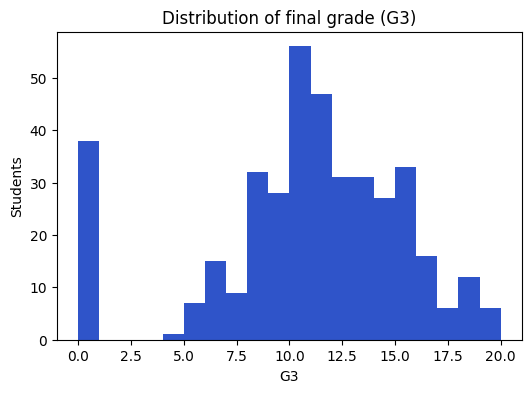

In [7]:
plt.figure(figsize=(6,4))
plt.hist(df["G3"], bins=20, color="#2f54c9")
plt.title("Distribution of final grade (G3)")
plt.xlabel("G3"); plt.ylabel("Students"); plt.show()

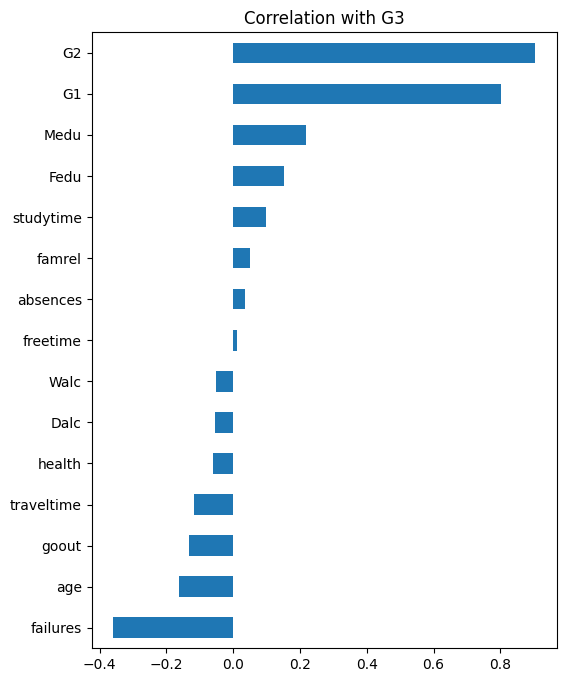

In [8]:
num = df.select_dtypes("number").corr()["G3"].drop("G3").sort_values()
num.plot(kind="barh", figsize=(6,8), title="Correlation with G3")
plt.show()

## 3. Prepare data
We **drop G1 and G2** (earlier period grades). They make prediction too easy because G3 is almost the same as G2. Without them the model has to learn from habits, which is more honest and more interesting.

In [9]:
X = df.drop(columns=["G1","G2","G3"])
y = df["G3"]

cat_cols = X.select_dtypes("object").columns.tolist()
num_cols = [c for c in X.columns if c not in cat_cols]

prep = ColumnTransformer([("cat", OneHotEncoder(handle_unknown="ignore"), cat_cols)],
                         remainder="passthrough")

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
print(len(X_train), "train /", len(X_test), "test")

316 train / 79 test


## 4. Train models

In [10]:
models = {
    "Linear Regression": LinearRegression(),
    "Random Forest": RandomForestRegressor(n_estimators=200, random_state=42),
}
results = {}
for name, m in models.items():
    pipe = Pipeline([("prep", prep), ("model", m)]).fit(X_train, y_train)
    pred = pipe.predict(X_test)
    results[name] = (pipe, pred)
    print(f"{name:18s} MAE={mean_absolute_error(y_test,pred):.2f}  R2={r2_score(y_test,pred):.2f}")

Linear Regression  MAE=3.40  R2=0.14
Random Forest      MAE=2.97  R2=0.31


## 5. Evaluate
MAE = average error in grade points. Lower is better. R2 closer to 1 is better.

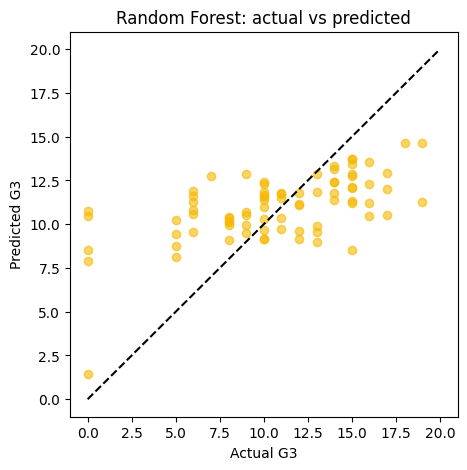

In [11]:
pipe, pred = results["Random Forest"]
plt.figure(figsize=(5,5))
plt.scatter(y_test, pred, alpha=.6, color="#f5b800")
plt.plot([0,20],[0,20],"k--")
plt.xlabel("Actual G3"); plt.ylabel("Predicted G3"); plt.title("Random Forest: actual vs predicted")
plt.show()

## 6. Which features matter most?

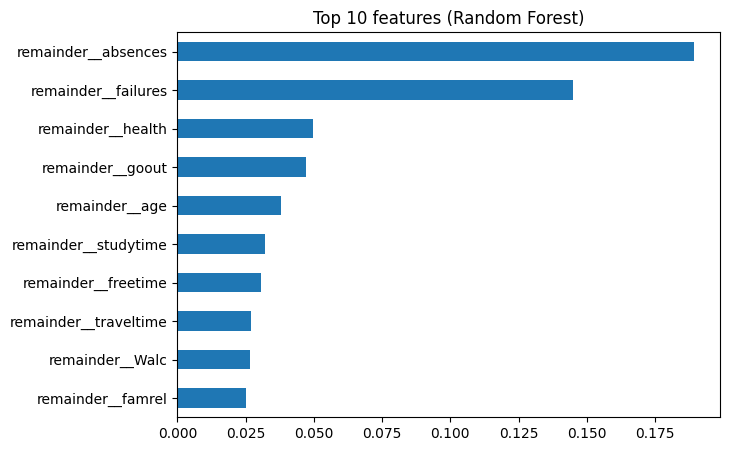

In [12]:
names = pipe.named_steps["prep"].get_feature_names_out()
imp = pd.Series(pipe.named_steps["model"].feature_importances_, index=names).sort_values().tail(10)
imp.plot(kind="barh", figsize=(7,5), title="Top 10 features (Random Forest)")
plt.show()

## Conclusion

- Random Forest did better than Linear Regression.
- Random Forest average error (MAE) is 2.97 marks. Linear Regression is 3.40 marks.
- R² is 0.31 for Random Forest and 0.14 for Linear Regression. Higher is better.
- The most important features are absences and failures.
- The model is not very accurate for students with very low or very high marks.
- The data is small (395 students), so the model is good for finding patterns, not for big decisions.
- Next, I can tune the model and try more data.
